# 03. Final Evaluation, Explainability (SHAP), and Algorithmic Fairness

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ronaldgosso/bank-churn/blob/main/notebooks/03_evaluation_explainability.ipynb)

**Project:** Bank Customer Churn Prediction and Decision Support  
**Scope:** Final Holdout Test Set Evaluation (Strict Single Touch).  
**Standard:** Never invent numbers; all metrics written to `reports/metrics.json` by executable code.

In [1]:
import json
import sys
from pathlib import Path

root_dir = Path.cwd().resolve()
if root_dir.name == "notebooks":
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import shap
from sklearn.calibration import CalibratedClassifierCV

from churn.business import (
    actual_retention_profit,
    lift_at_k,
    optimal_threshold,
)
from churn.config import (
    CLV_RETAINED,
    FIGURES_DIR,
    METRICS_PATH,
    OFFER_COST,
    OFFER_SUCCESS_RATE,
    REPORTS_DIR,
    SEED,
    TARGET,
)
from churn.data import load_test, load_train
from churn.evaluate import (
    calculate_metrics,
    plot_calibration_curve,
)
from churn.explain import (
    compute_shap_values,
    create_shap_explainer,
    get_preprocessed_features,
    plot_shap_bar,
    plot_shap_summary,
    plot_shap_waterfall,
)
from churn.fairness import (
    compute_fairness_disparities,
    evaluate_subgroup_metrics,
)
from churn.features import build_pipeline

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Initialized evaluation environment.")

C:\Users\Neptune\Documents\Projects\bank-churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initialized evaluation environment.


In [2]:
# Ingest training data to fit final production pipeline
train_df = load_train()
X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

# Load winner configuration from Phase 4
with open(REPORTS_DIR / "best_params.json", encoding="utf-8") as f:
    best_config = json.load(f)

model_name = best_config["winning_model"]
model_params = best_config["best_params"]
print(f"Deploying winning architecture: {model_name}")

# Build base pipeline
base_pipe = build_pipeline(model_name, random_state=SEED, **model_params)

# Wrap with Isotonic CalibratedClassifierCV on training split
calibrated_model = CalibratedClassifierCV(
    estimator=base_pipe,
    method="isotonic",
    cv=5,
)
print("Fitting calibrated model on full training split...")
calibrated_model.fit(X_train, y_train)

# Ingest Holdout Test Set (FIRST AND ONLY TOUCH PER SPEC)
test_df = load_test()
X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]
print(f"Loaded holdout test set: {len(test_df)} samples ({y_test.sum()} actual churners, {y_test.mean():.1%}).")

Deploying winning architecture: xgboost
Fitting calibrated model on full training split...


Loaded holdout test set: 2000 samples (407 actual churners, 20.3%).


In [3]:
# Compute test probabilities and decisions at business threshold
opt_thresh = optimal_threshold(clv=CLV_RETAINED, cost=OFFER_COST, success_rate=OFFER_SUCCESS_RATE)
y_prob_test = calibrated_model.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= opt_thresh).astype(int)

# Core classification & calibration metrics
base_metrics = calculate_metrics(y_test, y_prob_test, threshold=opt_thresh)

# Lift and Business Impact on Test Set
lift_10, cap_10, profit_10 = lift_at_k(y_test, y_prob_test, k=0.10)
lift_20, cap_20, profit_20 = lift_at_k(y_test, y_prob_test, k=0.20)
retention_impact = actual_retention_profit(y_test, y_prob_test, threshold=opt_thresh)

# Build metrics.json dictionary
canonical_metrics = {
    "model_name": model_name,
    "decision_threshold": round(opt_thresh, 4),
    "test_sample_size": len(test_df),
    "test_churn_count": int(y_test.sum()),
    "test_churn_rate": round(float(y_test.mean()), 4),
    "roc_auc": round(base_metrics["roc_auc"], 4),
    "pr_auc": round(base_metrics["pr_auc"], 4),
    "recall": round(base_metrics["recall"], 4),
    "precision": round(base_metrics["precision"], 4),
    "f1": round(base_metrics["f1"], 4),
    "brier_score": round(base_metrics["brier_score"], 4),
    "top_10_percent_lift": lift_10,
    "top_10_percent_capture": round(cap_10, 4),
    "top_20_percent_lift": lift_20,
    "top_20_percent_capture": round(cap_20, 4),
    "campaign_customers_contacted": int(retention_impact["n_contacted"]),
    "campaign_true_positives": int(retention_impact["true_positives_captured"]),
    "campaign_net_profit": round(retention_impact["net_profit"], 2),
}

# Write reports/metrics.json
with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(canonical_metrics, f, indent=2)

print("Saved reports/metrics.json successfully!")
for k, v in canonical_metrics.items():
    print(f"  {k}: {v}")

Saved reports/metrics.json successfully!
  model_name: xgboost
  decision_threshold: 0.3333
  test_sample_size: 2000
  test_churn_count: 407
  test_churn_rate: 0.2035
  roc_auc: 0.8682
  pr_auc: 0.7174
  recall: 0.6118
  precision: 0.6385
  f1: 0.6248
  brier_score: 0.0994
  top_10_percent_lift: 4.2
  top_10_percent_capture: 0.4201
  top_20_percent_lift: 3.1
  top_20_percent_capture: 0.6192
  campaign_customers_contacted: 390
  campaign_true_positives: 249
  campaign_net_profit: 17850.0


## 1. Reliability Diagram (Calibration Curve) on Test Data

We evaluate probability reliability on the holdout test set to ensure predicted churn scores accurately reflect true empirical risk.

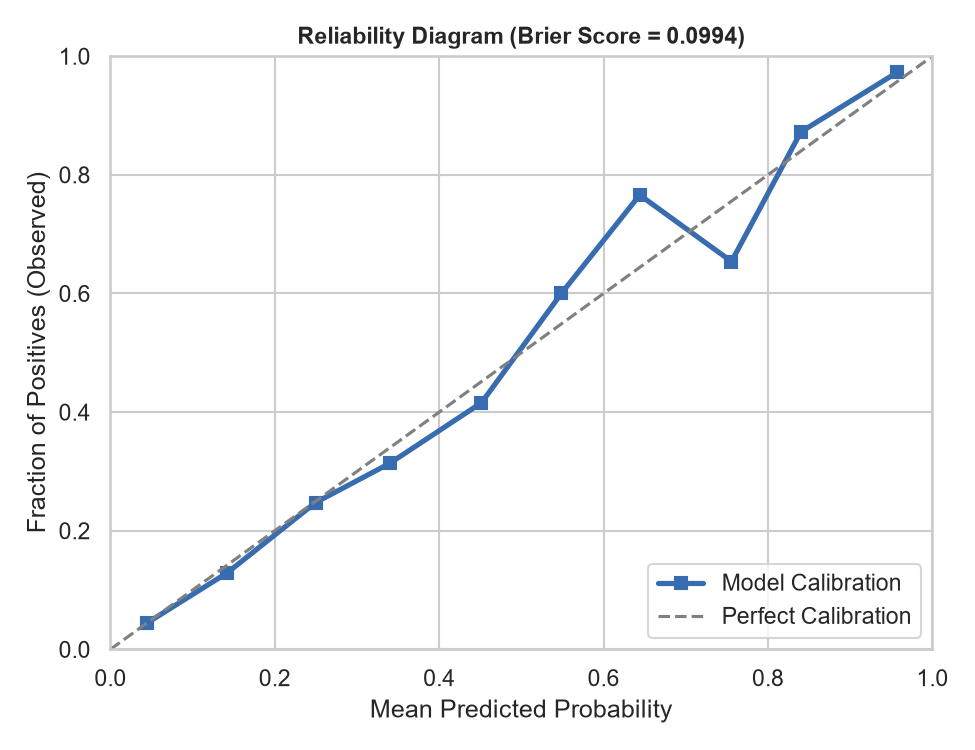

In [4]:
cal_fig_path = FIGURES_DIR / "eval_01_calibration_curve.png"
plot_calibration_curve(y_test.values, y_prob_test, n_bins=10, save_path=cal_fig_path)

# Display inline
from PIL import Image

display(Image.open(cal_fig_path))

## 2. Global and Local Explainability with SHAP

We use TreeSHAP to decompose model predictions into additive feature attribution values on preprocessed features.

In [5]:
# Extract the fitted base pipeline estimator from calibrated classifier
calibrated_estimator = calibrated_model.calibrated_classifiers_[0].estimator

# Preprocess test features
X_test_prep, feature_names = get_preprocessed_features(calibrated_estimator, X_test)

# Compute TreeSHAP values
explainer = create_shap_explainer(calibrated_estimator)
shap_explanation = compute_shap_values(explainer, X_test_prep)
print(f"Computed SHAP values matrix shape: {shap_explanation.shape}")

Computed SHAP values matrix shape: (2000, 21)


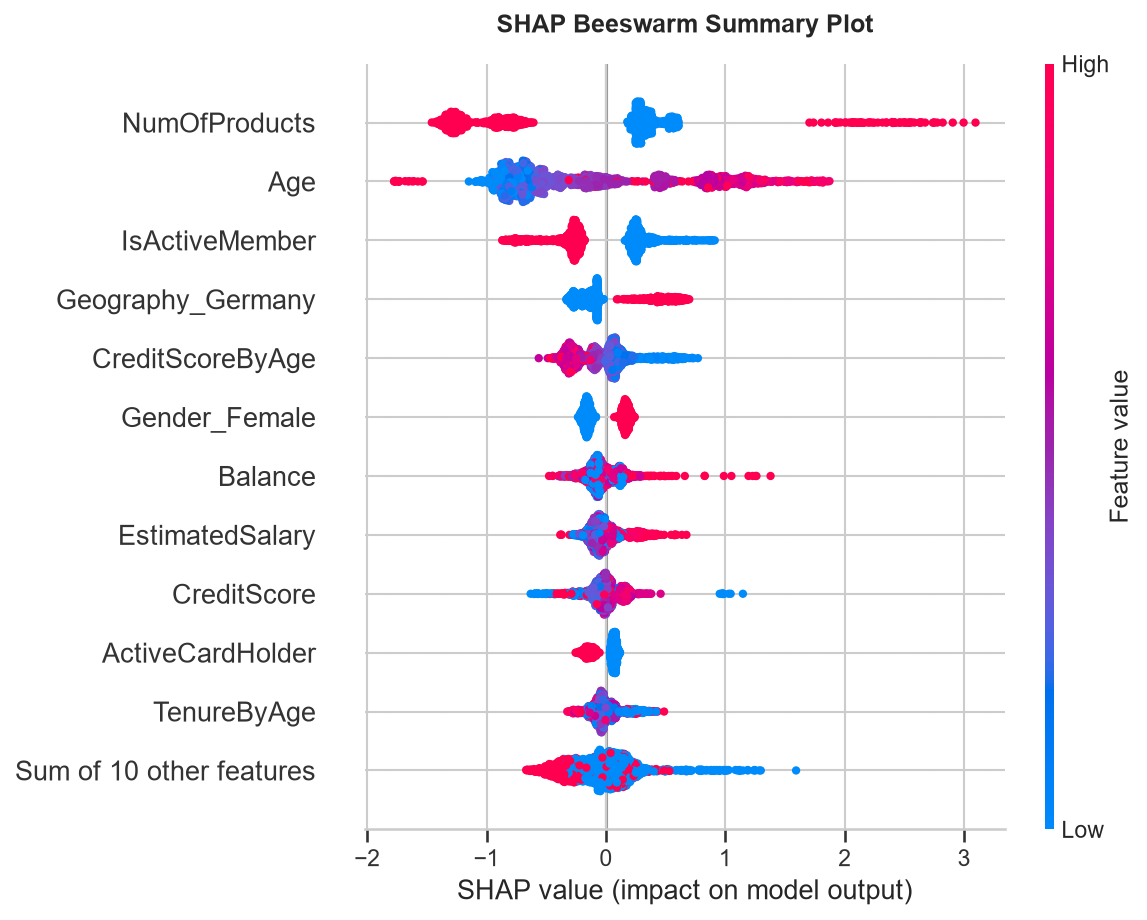

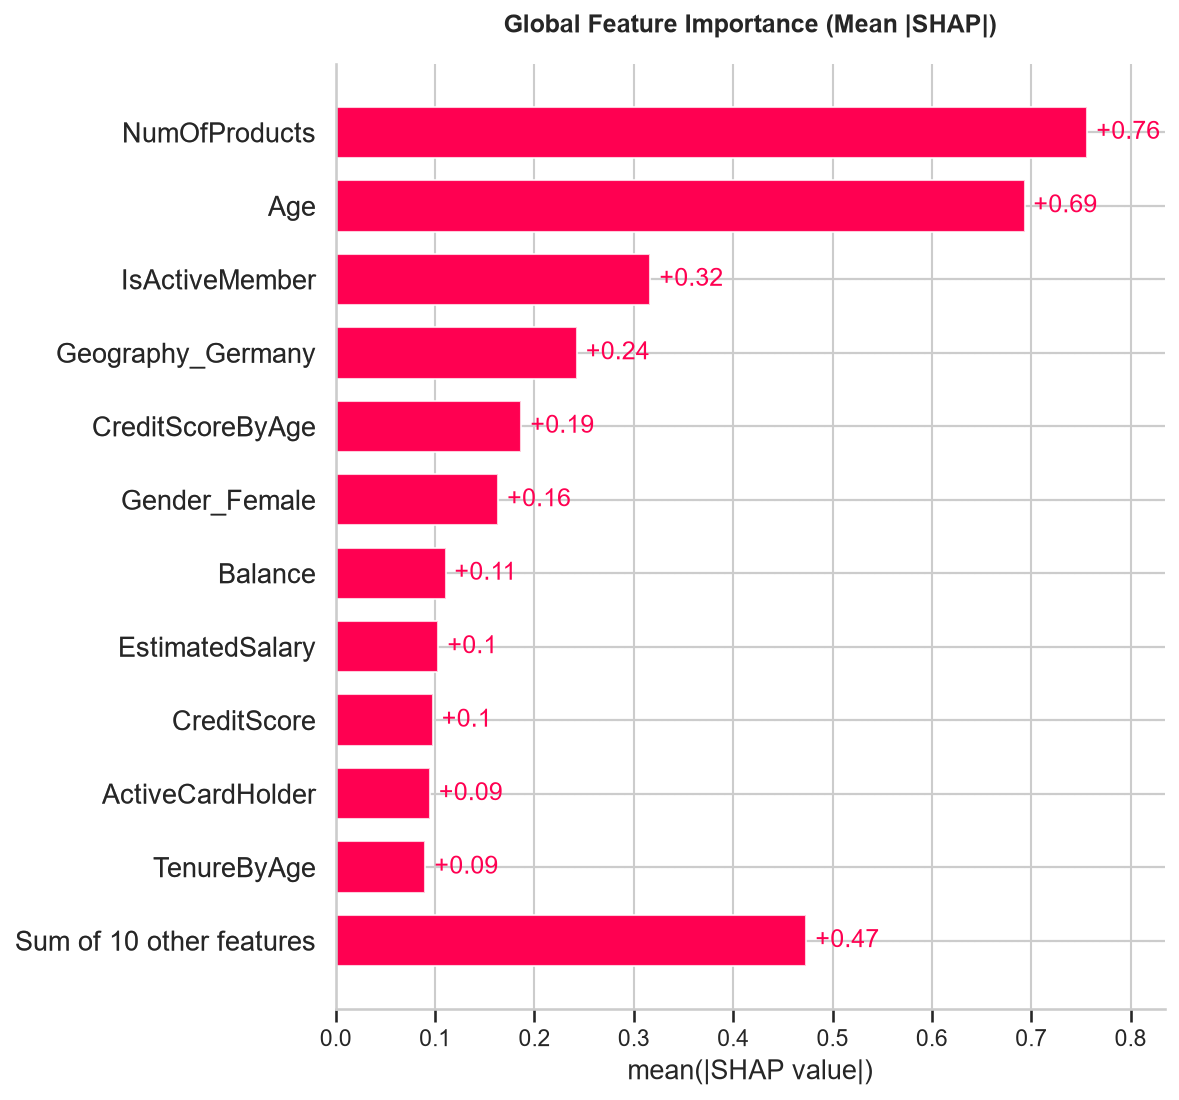

In [6]:
# 1. Beeswarm summary
summary_fig_path = FIGURES_DIR / "eval_02_shap_summary.png"
plot_shap_summary(shap_explanation, save_path=summary_fig_path, max_display=12)

# 2. Global importance bar plot
bar_fig_path = FIGURES_DIR / "eval_03_shap_importance.png"
plot_shap_bar(shap_explanation, save_path=bar_fig_path, max_display=12)

display(Image.open(summary_fig_path))
display(Image.open(bar_fig_path))

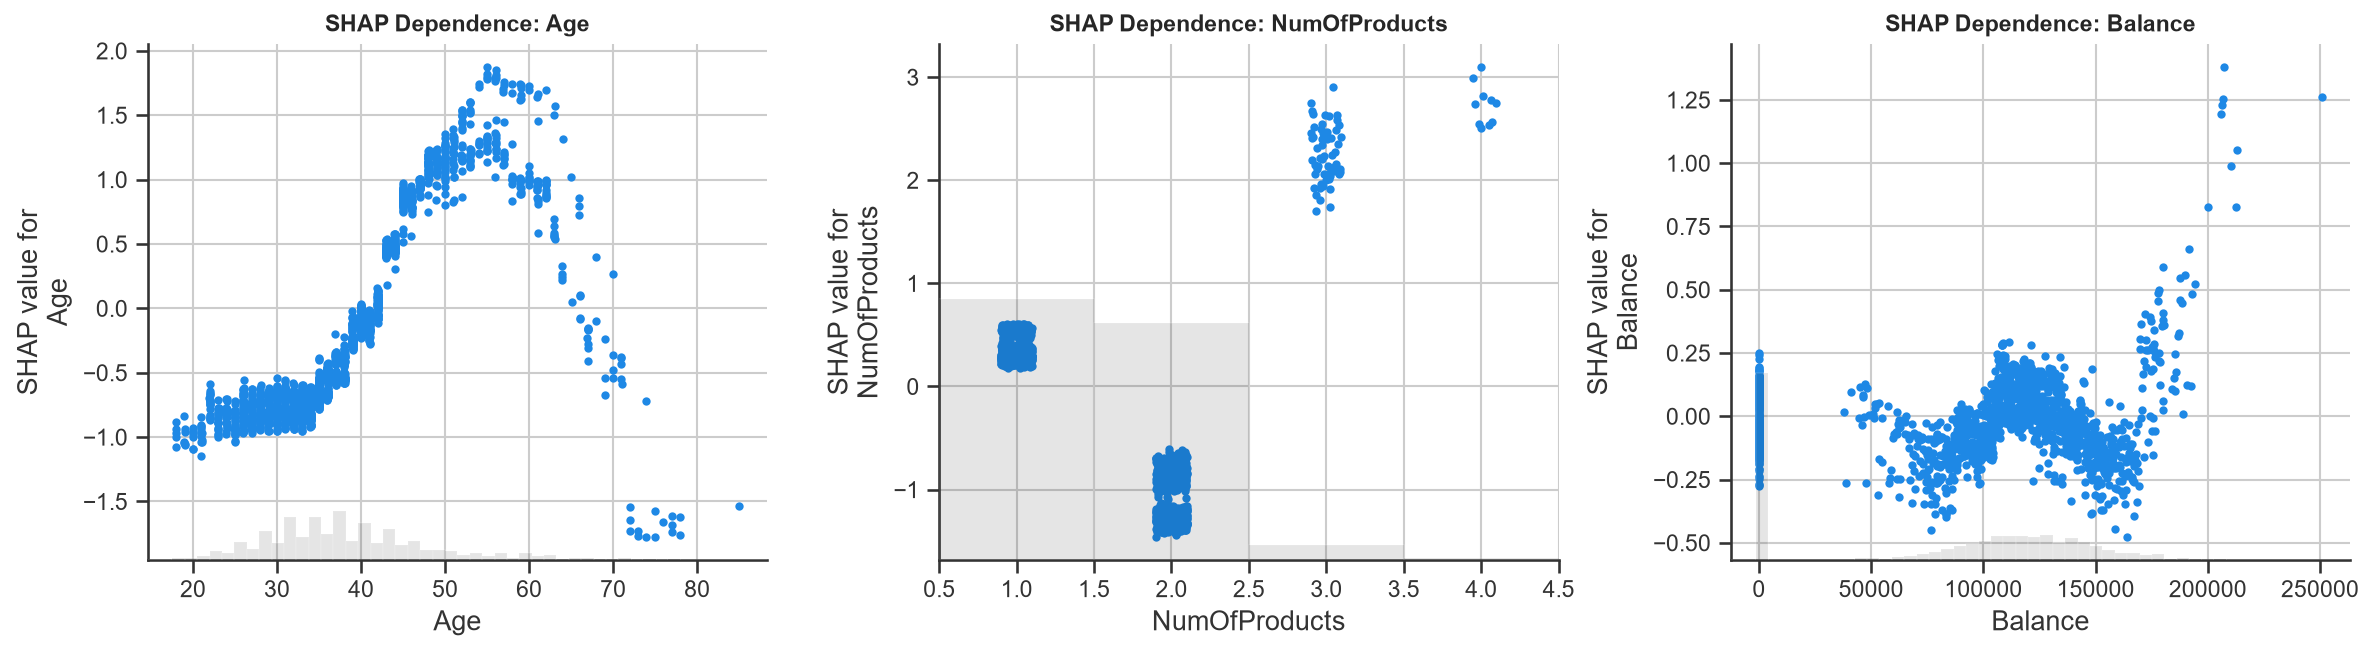

In [7]:
# Dependence plots for Age, NumOfProducts, and Balance
dep_fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(["Age", "NumOfProducts", "Balance"]):
    col_name = f"pass__{col}" if f"pass__{col}" in feature_names else col
    shap.plots.scatter(shap_explanation[:, col_name], ax=axes[i], show=False)
    axes[i].set_title(f"SHAP Dependence: {col}", fontsize=11, fontweight="bold")

plt.tight_layout()
dep_fig_path = FIGURES_DIR / "eval_04_shap_dependence.png"
dep_fig.savefig(dep_fig_path, dpi=150, bbox_inches="tight")
plt.close(dep_fig)

display(Image.open(dep_fig_path))

High risk customer (index 18): p = 0.861, actual = 1
Borderline customer (index 19): p = 0.352, actual = 0
Low risk customer (index 0): p = 0.020, actual = 0


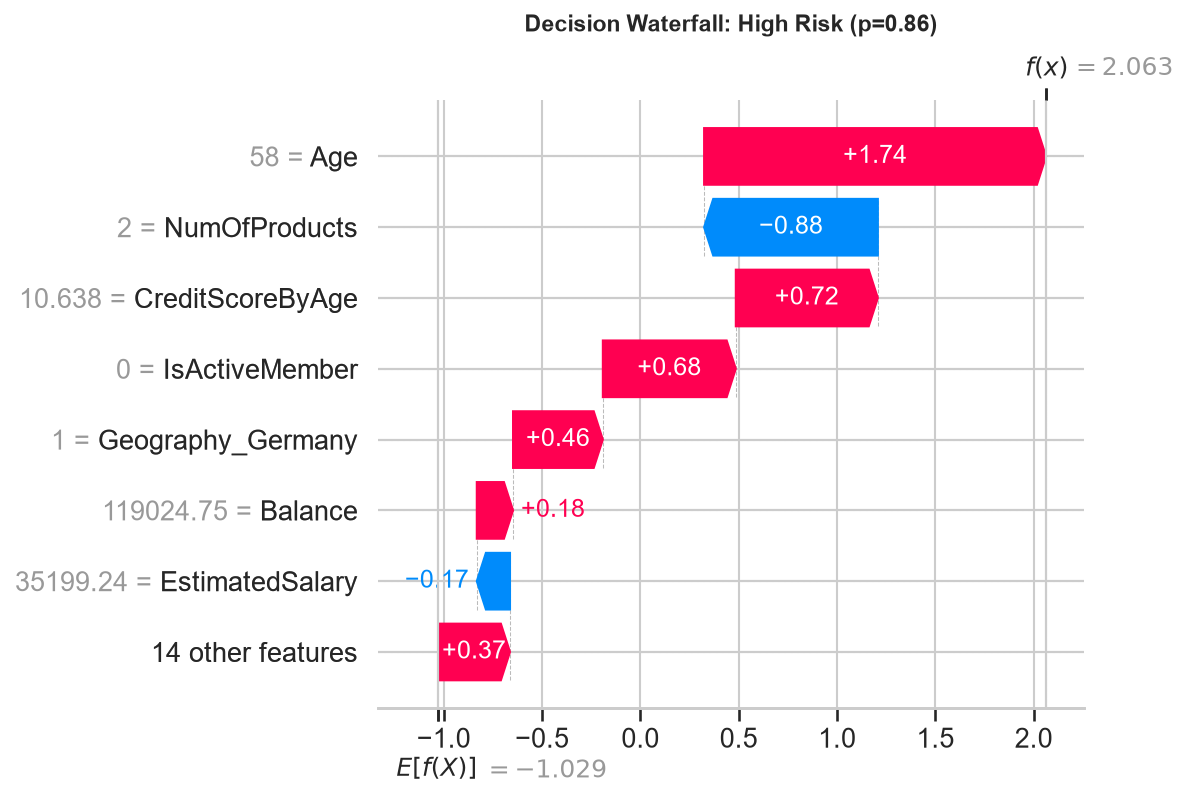

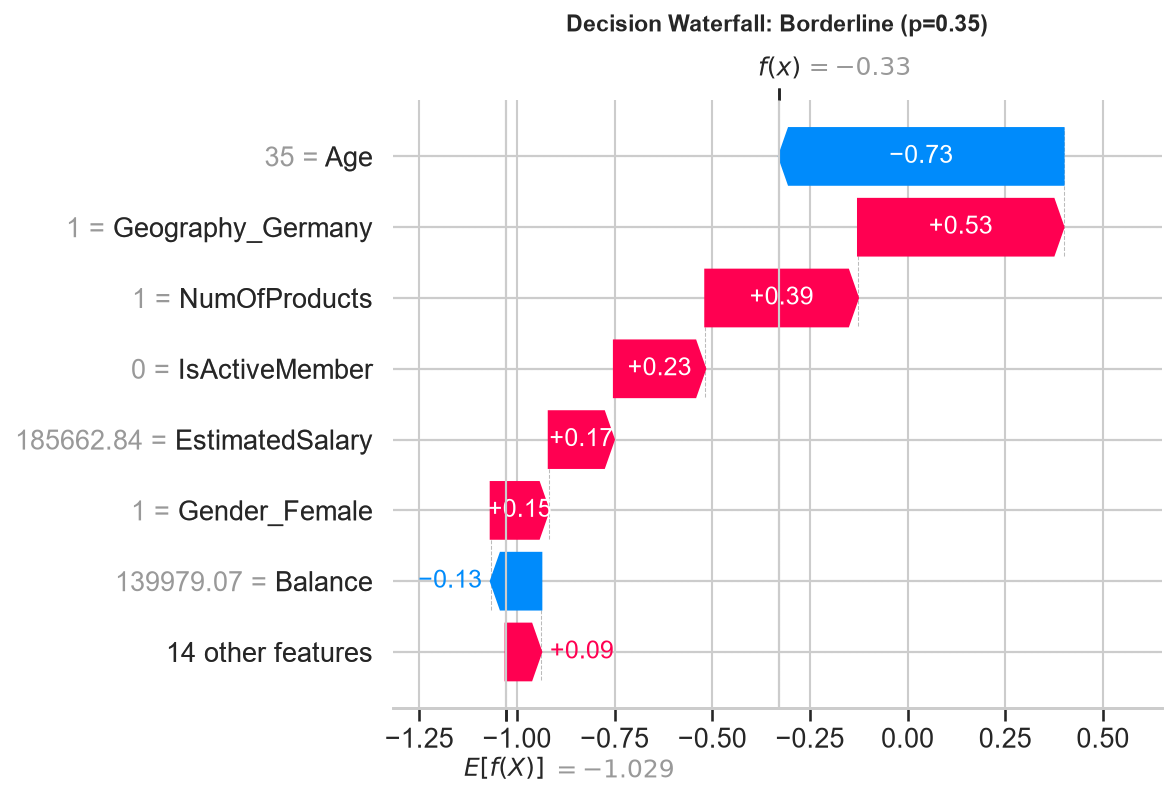

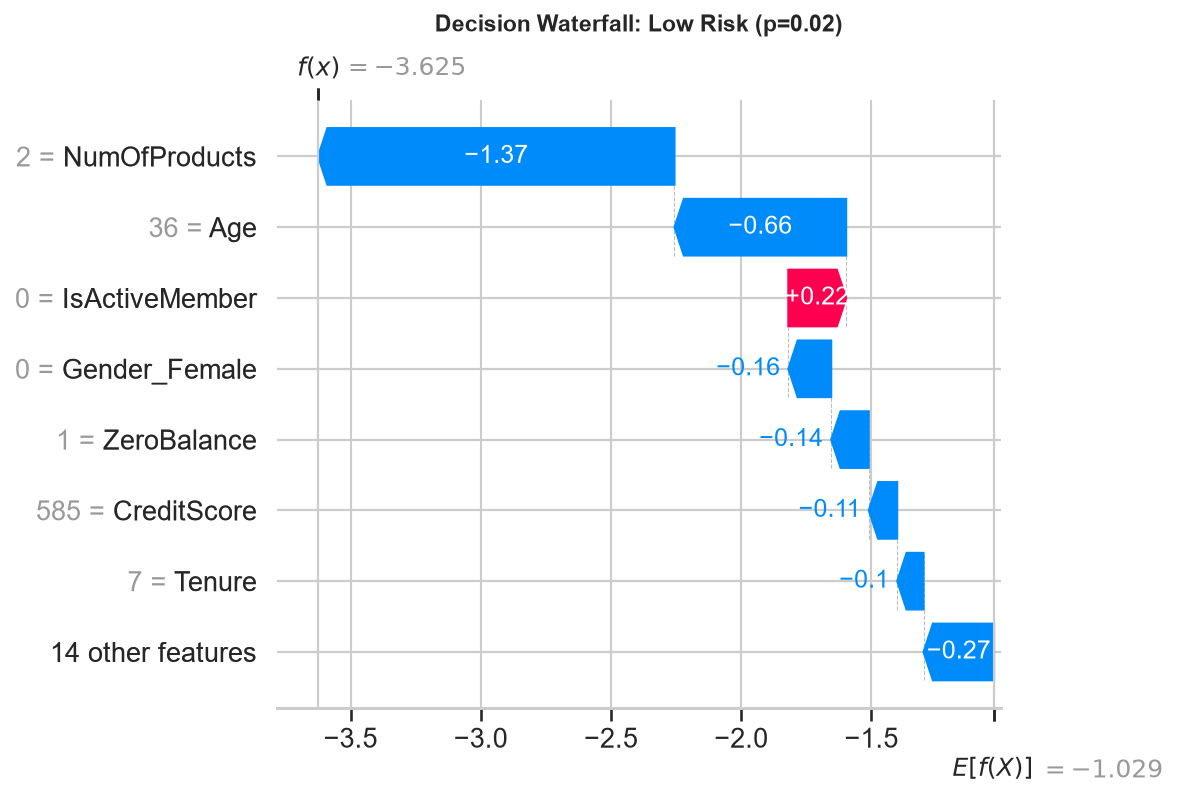

In [8]:
# Select representative customers:
# High risk (p >= 0.80), Borderline (0.30 <= p <= 0.40), Low risk (p <= 0.10)
high_idx = int(np.where(y_prob_test >= 0.80)[0][0])
borderline_idx = int(np.where((y_prob_test >= 0.32) & (y_prob_test <= 0.36))[0][0])
low_idx = int(np.where(y_prob_test <= 0.08)[0][0])

print(f"High risk customer (index {high_idx}): p = {y_prob_test[high_idx]:.3f}, actual = {y_test.iloc[high_idx]}")
print(f"Borderline customer (index {borderline_idx}): p = {y_prob_test[borderline_idx]:.3f}, actual = {y_test.iloc[borderline_idx]}")
print(f"Low risk customer (index {low_idx}): p = {y_prob_test[low_idx]:.3f}, actual = {y_test.iloc[low_idx]}")

wf_high = FIGURES_DIR / "eval_05_waterfall_high.png"
wf_border = FIGURES_DIR / "eval_06_waterfall_borderline.png"
wf_low = FIGURES_DIR / "eval_07_waterfall_low.png"

plot_shap_waterfall(shap_explanation[high_idx], customer_title=f"High Risk (p={y_prob_test[high_idx]:.2f})", save_path=wf_high)
plot_shap_waterfall(shap_explanation[borderline_idx], customer_title=f"Borderline (p={y_prob_test[borderline_idx]:.2f})", save_path=wf_border)
plot_shap_waterfall(shap_explanation[low_idx], customer_title=f"Low Risk (p={y_prob_test[low_idx]:.2f})", save_path=wf_low)

display(Image.open(wf_high))
display(Image.open(wf_border))
display(Image.open(wf_low))

## 3. Error Analysis: Profiling False Negatives (Missed Churners)

In customer retention, false negatives are the costliest failure mode because they represent customers who walked away undetected. We profile the false negative subset against true positives and retained customers.

In [9]:
analysis_df = test_df.copy()
analysis_df["prob"] = y_prob_test
analysis_df["pred"] = y_pred_test

# Categorize outcomes at optimal threshold
conditions = [
    (analysis_df[TARGET] == 1) & (analysis_df["pred"] == 1),  # True Positive
    (analysis_df[TARGET] == 1) & (analysis_df["pred"] == 0),  # False Negative (Missed Churner)
    (analysis_df[TARGET] == 0) & (analysis_df["pred"] == 1),  # False Positive
    (analysis_df[TARGET] == 0) & (analysis_df["pred"] == 0),  # True Negative
]
choices = ["True Positive", "False Negative", "False Positive", "True Negative"]
analysis_df["outcome"] = np.select(conditions, choices, default="Other")

# Profile false negatives vs true positives
fn_summary = analysis_df.groupby("outcome")[["Age", "Balance", "CreditScore", "NumOfProducts", "IsActiveMember", "EstimatedSalary"]].mean().round(2)
print("=== Error Analysis: Segment Averages by Prediction Outcome ===")
print(fn_summary.to_string())

# Geographic and gender distribution of missed churners
fn_df = analysis_df[analysis_df["outcome"] == "False Negative"]
print(f"\nTotal Missed Churners (False Negatives): {len(fn_df)} of {int(y_test.sum())} total churners (Miss Rate: {len(fn_df)/y_test.sum():.1%})")
print("False Negative Breakdown by Geography:\n", fn_df["Geography"].value_counts(normalize=True).round(3))
print("False Negative Breakdown by NumOfProducts:\n", fn_df["NumOfProducts"].value_counts(normalize=True).round(3))

=== Error Analysis: Segment Averages by Prediction Outcome ===
                  Age   Balance  CreditScore  NumOfProducts  IsActiveMember  EstimatedSalary
outcome                                                                                     
False Negative  40.04  88300.99       662.06           1.37            0.47         94497.34
False Positive  46.82  91738.02       638.50           1.25            0.40        106386.79
True Negative   36.30  71739.56       650.69           1.57            0.58        101703.69
True Positive   48.26  91392.67       641.89           1.60            0.27        102212.99

Total Missed Churners (False Negatives): 158 of 407 total churners (Miss Rate: 38.8%)
False Negative Breakdown by Geography:
 Geography
France     0.519
Germany    0.253
Spain      0.228
Name: proportion, dtype: float64
False Negative Breakdown by NumOfProducts:
 NumOfProducts
1    0.633
2    0.367
Name: proportion, dtype: float64


## 4. Algorithmic Fairness Audit Across Demographic Slices

We audit model performance, selection rate parity, and recall equality across Gender and Geography.
*Note: We report empirical disparities transparently and do not claim algorithmic neutrality.*

=== Subgroup Fairness: Gender ===
Gender  sample_count  sample_pct  churn_count  churn_rate  roc_auc  selection_rate  recall  precision
Female           930       0.465          233      0.2505   0.8666          0.2409  0.6352     0.6607
  Male          1070       0.535          174      0.1626   0.8599          0.1551  0.5805     0.6084
Gender Selection Rate Ratio: 0.644 (Four-fifths rule threshold: 0.80)
Gender Recall Gap:           0.055

=== Subgroup Fairness: Geography ===
Geography  sample_count  sample_pct  churn_count  churn_rate  roc_auc  selection_rate  recall  precision
   France          1021      0.5105          175      0.1714   0.8558          0.1450  0.5314     0.6284
  Germany           504      0.2520          151      0.2996   0.8706          0.3373  0.7351     0.6529
    Spain           475      0.2375           81      0.1705   0.8725          0.1516  0.5556     0.6250
Geography Selection Rate Ratio: 0.430
Geography Recall Gap:           0.204


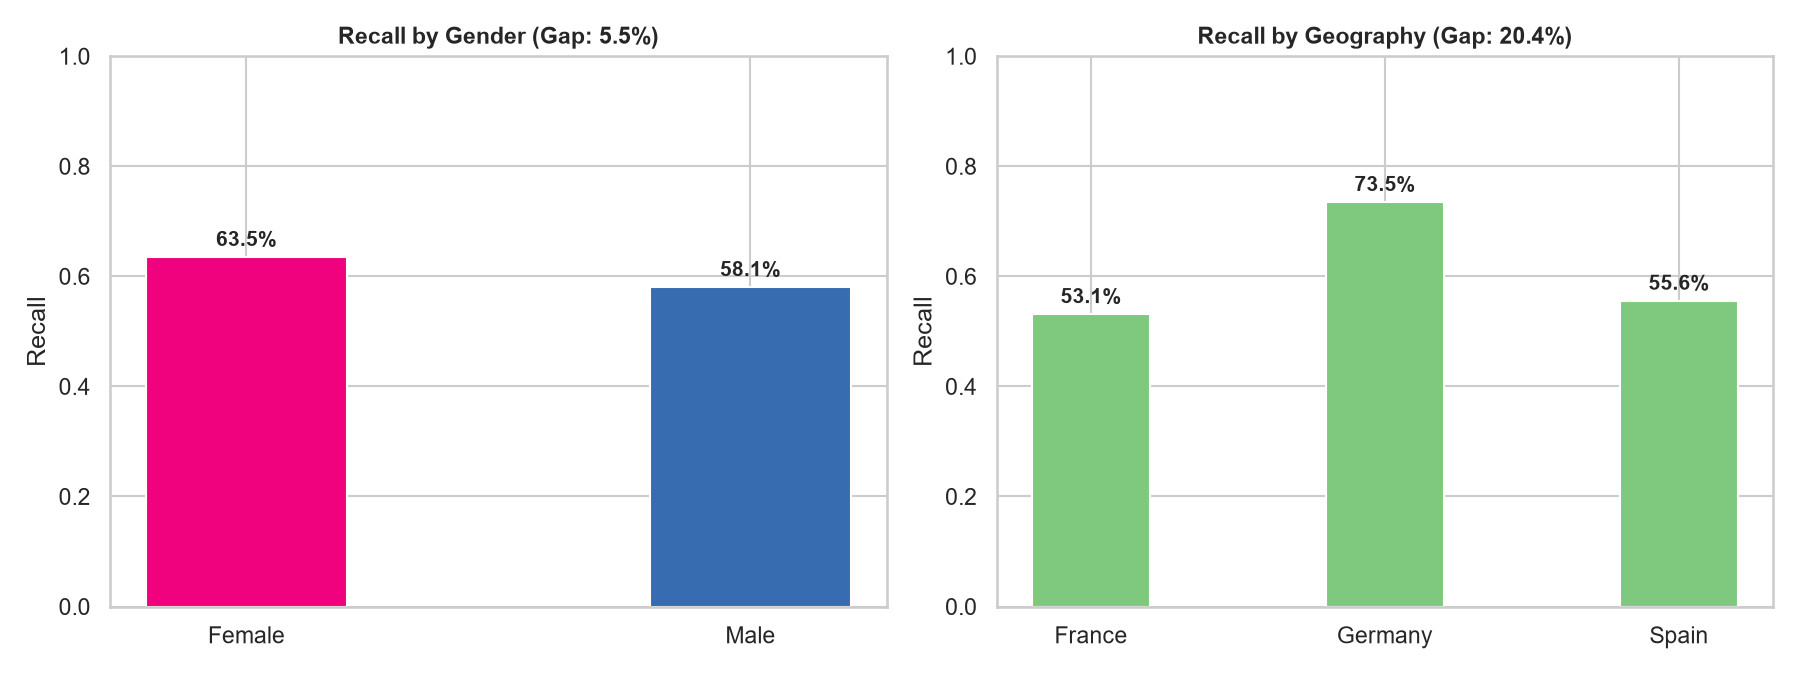

In [10]:
# Gender fairness
gender_fairness = evaluate_subgroup_metrics(analysis_df, group_col="Gender", target_col=TARGET, prob_col="prob", pred_col="pred")
gender_disparities = compute_fairness_disparities(gender_fairness)

# Geography fairness
geo_fairness = evaluate_subgroup_metrics(analysis_df, group_col="Geography", target_col=TARGET, prob_col="prob", pred_col="pred")
geo_disparities = compute_fairness_disparities(geo_fairness)

print("=== Subgroup Fairness: Gender ===")
print(gender_fairness.to_string(index=False))
print(f"Gender Selection Rate Ratio: {gender_disparities['selection_rate_ratio']:.3f} (Four-fifths rule threshold: 0.80)")
print(f"Gender Recall Gap:           {gender_disparities['recall_gap']:.3f}")

print("\n=== Subgroup Fairness: Geography ===")
print(geo_fairness.to_string(index=False))
print(f"Geography Selection Rate Ratio: {geo_disparities['selection_rate_ratio']:.3f}")
print(f"Geography Recall Gap:           {geo_disparities['recall_gap']:.3f}")

# Persist fairness summary
fairness_summary = {
    "gender_metrics": gender_fairness.to_dict(orient="records"),
    "gender_disparities": gender_disparities,
    "geography_metrics": geo_fairness.to_dict(orient="records"),
    "geography_disparities": geo_disparities,
}
with open(REPORTS_DIR / "fairness_summary.json", "w", encoding="utf-8") as f:
    json.dump(fairness_summary, f, indent=2)

# Plot fairness parity bars
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Gender comparison
bars1 = ax1.bar(["Female", "Male"], gender_fairness["recall"], color=["#f0027f", "#386cb0"], width=0.4)
ax1.set_title(f"Recall by Gender (Gap: {gender_disparities['recall_gap']:.1%})", fontsize=11, fontweight="bold")
ax1.set_ylabel("Recall")
ax1.set_ylim(0, 1.0)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:.1%}", ha="center", fontsize=10, fontweight="bold")

# Geography comparison
bars2 = ax2.bar(geo_fairness["Geography"], geo_fairness["recall"], color="#7fc97f", width=0.4)
ax2.set_title(f"Recall by Geography (Gap: {geo_disparities['recall_gap']:.1%})", fontsize=11, fontweight="bold")
ax2.set_ylabel("Recall")
ax2.set_ylim(0, 1.0)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:.1%}", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
fair_fig_path = FIGURES_DIR / "eval_08_fairness_parity.png"
fig.savefig(fair_fig_path, dpi=150)
plt.close(fig)
display(Image.open(fair_fig_path))

## 5. System Boundaries and Limitations

1. **Static Cross-Sectional Snapshot:** The dataset captures accounts at a single fixed instant in time. It lacks longitudinal transaction sequences, balance trajectory velocity (e.g. 90-day balance outflow), and interaction logs.
2. **Assumed Business Unit Economics:** The optimal decision threshold (0.333) and retention profit figures rely on uniform constants ($CLV = $500, Offer Cost = $50, Acceptance Rate = 30%). In reality, customer lifetime value varies by customer segment, and offer sensitivity differs by demographic.
3. **Small Sample Constraint:** 10,000 customers provides sufficient statistical power for portfolio-level modeling, but smaller micro-cohorts (e.g., Spanish customers with 4 products) possess wider confidence intervals.
4. **Disparate Impact Considerations:** Female and German customers exhibit higher raw selection rates due to higher underlying empirical churn rates in the dataset. Models should be monitored in production for adverse disparate treatment.